# Supervised models Notebook

### This notebook is used to show different algorithms and their accuracy

In [19]:
# imports to be used in the notebook
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)
from time import perf_counter
from src.data import X_sent_val, X_sent_train, X_img_val, X_img_train, y_sent_val, y_sent_train, y_img_val, y_img_train
from src.models.knn import predict_knn, normalize_rows, predict_knn_weighted
from src.models.decision_tree import CustomDecisionTree
from src.models.random_forest import CustomRandomForest

## 1. k-NN Algorithm

### 1.1 Non weighted k-NN using only Euclidian distance

In [4]:
#testing different k values for the image sets
for k in [1, 3, 5, 10, 20]:
    predictions = predict_knn(X_img_train, y_img_train, X_img_val, k=k)
    accuracy = (predictions == y_img_val).mean()
    print(f"k={k:2d} | Image validation accuracy: {accuracy:.2%}")

#testing different k values for the sentiment sets
for k in [1, 3, 5, 10, 20]:
    predictions = predict_knn(X_sent_train, y_sent_train, X_sent_val, k=k)
    accuracy = (predictions == y_sent_val).mean()
    print(f"k={k:2d} | Sentiment validation accuracy: {accuracy:.2%}")

k= 1 | Image validation accuracy: 53.08%
k= 3 | Image validation accuracy: 42.65%
k= 5 | Image validation accuracy: 42.00%
k=10 | Image validation accuracy: 38.77%
k=20 | Image validation accuracy: 35.27%
k= 1 | Sentiment validation accuracy: 50.12%
k= 3 | Sentiment validation accuracy: 52.71%
k= 5 | Sentiment validation accuracy: 53.87%
k=10 | Sentiment validation accuracy: 54.92%
k=20 | Sentiment validation accuracy: 57.46%


### 1.2 Non weighted k-NN using Euclidian distance + normalization

In [5]:
#testing different k values for the image sets
for k in [1, 3, 5, 10, 20]:
    predictions = predict_knn(normalize_rows(X_img_train), y_img_train, normalize_rows(X_img_val), k=k)
    accuracy = (predictions == y_img_val).mean()
    print(f"k={k:2d} | Image validation accuracy: {accuracy:.2%}")


#testing different k values for the sentiment sets
for k in [1, 3, 5, 10, 20]:
    predictions = predict_knn(normalize_rows(X_sent_train), y_sent_train, normalize_rows(X_sent_val), k=k)
    accuracy = (predictions == y_sent_val).mean()
    print(f"k={k:2d} | Sentiment validation accuracy: {accuracy:.2%}")

k= 1 | Image validation accuracy: 53.08%
k= 3 | Image validation accuracy: 42.65%
k= 5 | Image validation accuracy: 42.00%
k=10 | Image validation accuracy: 38.75%
k=20 | Image validation accuracy: 35.30%
k= 1 | Sentiment validation accuracy: 51.17%
k= 3 | Sentiment validation accuracy: 52.29%
k= 5 | Sentiment validation accuracy: 54.67%
k=10 | Sentiment validation accuracy: 55.96%
k=20 | Sentiment validation accuracy: 56.79%


### 1.3 Weighted k-NN using only Euclidian distance
- For the image sets, only k = 1, 3, 5 will be used as it has proven more accuracy.
- For the sentiment sets, k = 10, 20, 30, 60, 100, 200 will be used for the same reason.

In [6]:
#testing different k values for the image sets
for k in [1, 3, 5]:
    predictions = predict_knn_weighted(X_img_train, y_img_train, X_img_val, k=k)
    accuracy = (predictions == y_img_val).mean()
    print(f"k={k} | Weighted image validation accuracy: {accuracy:.2%}")

#testing different k values for the sentiment sets
for k in [10, 20, 30, 60, 100, 200]:
    predictions = predict_knn_weighted(X_sent_train, y_sent_train, X_sent_val, k=k)
    accuracy = (predictions == y_sent_val).mean()
    print(f"k={k} | Weighted sentiment validation accuracy: {accuracy:.2%}")


k=1 | Weighted image validation accuracy: 53.08%
k=3 | Weighted image validation accuracy: 52.10%
k=5 | Weighted image validation accuracy: 49.10%
k=10 | Weighted sentiment validation accuracy: 55.92%
k=20 | Weighted sentiment validation accuracy: 57.21%
k=30 | Weighted sentiment validation accuracy: 57.79%
k=60 | Weighted sentiment validation accuracy: 58.75%
k=100 | Weighted sentiment validation accuracy: 58.08%
k=200 | Weighted sentiment validation accuracy: 57.21%


### 1.4 Weighted k-NN using Euclidian distance + normalization
- For the image sets, only k = 1, 3, 5 will be used as it has proven more accuracy.
- For the sentiment sets, k = 10, 20, 30, 60, 100, 200 will be used for the same reason.

In [7]:
#testing different k values for the image sets
for k in [1, 3, 5]:
    predictions = predict_knn_weighted(normalize_rows(X_img_train), y_img_train, normalize_rows(X_img_val), k=k)
    accuracy = (predictions == y_img_val).mean()
    print(f"k={k} | Weighted image validation accuracy: {accuracy:.2%}")

#testing different k values for the sentiment sets
for k in [10, 20, 30, 60, 100, 200]:
    predictions = predict_knn_weighted(normalize_rows(X_sent_train), y_sent_train, normalize_rows(X_sent_val), k=k)
    accuracy = (predictions == y_sent_val).mean()
    print(f"k={k} | Weighted sentiment validation accuracy: {accuracy:.2%}")


k=1 | Weighted image validation accuracy: 53.08%
k=3 | Weighted image validation accuracy: 52.10%
k=5 | Weighted image validation accuracy: 49.12%
k=10 | Weighted sentiment validation accuracy: 56.25%
k=20 | Weighted sentiment validation accuracy: 56.58%
k=30 | Weighted sentiment validation accuracy: 57.63%
k=60 | Weighted sentiment validation accuracy: 57.88%
k=100 | Weighted sentiment validation accuracy: 58.25%
k=200 | Weighted sentiment validation accuracy: 57.67%


## 2. Decision Trees and Random Forest Algorithms

### 2.1 Decision trees implementation

In [ ]:
# setting up the datasets for decision tree model
SEED_TREE = 42

DATASETS_TREE = {
    "Image": (
        X_img_train, X_img_val,
        y_img_train, y_img_val
    ),
    "Sentiment": (
        X_sent_train, X_sent_val,
        y_sent_train, y_sent_val
    )
}

for name, (Xtr, Xva, ytr, yva) in DATASETS_TREE.items():
    print(f"{name}: {Xtr.shape} training, {Xva.shape} validation")

Image: (16000, 500) training, (4000, 500) validation
Sentiment: (9600, 768) training, (2400, 768) validation


In [7]:
X_toy = np.array([
    [0, 0],
    [0, 1],
    [1, 0],
    [1, 1],
    [2, 0],
    [2, 1]
], dtype=np.float32)

y_toy = np.array([0, 0, 0, 1, 1, 1])

toy_tree = CustomDecisionTree(
    max_depth=3,
    min_samples_split=2,
    min_samples_leaf=1,
    n_thresholds=4
)

toy_tree.fit(X_toy, y_toy)

print("Predictions:", toy_tree.predict(X_toy))
print(
    "Training accuracy:",
    accuracy_score(y_toy, toy_tree.predict(X_toy))
)

Predictions: [0 0 0 1 1 1]
Training accuracy: 1.0


In [9]:
tree_results = []
best_trees = {}

for dataset, (Xtr, Xva, ytr, yva) in DATASETS_TREE.items():

    best_score = -1

    for depth in [5, 10, 15]:
        for leaf in [10, 30]:

            start = perf_counter()

            model = CustomDecisionTree(
                max_depth=depth,
                min_samples_leaf=leaf,
                min_samples_split=2 * leaf,
                n_thresholds=8,
                random_state=SEED_TREE
            )

            model.fit(Xtr, ytr)

            train_acc = accuracy_score(
                ytr, model.predict(Xtr)
            )

            val_acc = accuracy_score(
                yva, model.predict(Xva)
            )

            elapsed = perf_counter() - start

            tree_results.append({
                "Dataset": dataset,
                "Depth": depth,
                "Min leaf": leaf,
                "Train accuracy": train_acc,
                "Validation accuracy": val_acc,
                "Seconds": round(elapsed, 1)
            })

            print(
                f"{dataset} | Depth={depth} | Leaf={leaf} "
                f"| Train={train_acc:.3f} "
                f"| Validation={val_acc:.3f}"
            )

            if val_acc > best_score:
                best_score = val_acc
                best_trees[dataset] = model

tree_results_df = pd.DataFrame(tree_results)

display(
    tree_results_df.sort_values(
        ["Dataset", "Validation accuracy"],
        ascending=[True, False]
    )
)

Image | Depth=5 | Leaf=10 | Train=0.073 | Validation=0.063
Image | Depth=5 | Leaf=30 | Train=0.073 | Validation=0.063
Image | Depth=10 | Leaf=10 | Train=0.135 | Validation=0.088
Image | Depth=10 | Leaf=30 | Train=0.117 | Validation=0.088
Image | Depth=15 | Leaf=10 | Train=0.208 | Validation=0.096
Image | Depth=15 | Leaf=30 | Train=0.156 | Validation=0.096
Sentiment | Depth=5 | Leaf=10 | Train=0.528 | Validation=0.480
Sentiment | Depth=5 | Leaf=30 | Train=0.529 | Validation=0.481
Sentiment | Depth=10 | Leaf=10 | Train=0.723 | Validation=0.445
Sentiment | Depth=10 | Leaf=30 | Train=0.644 | Validation=0.455
Sentiment | Depth=15 | Leaf=10 | Train=0.773 | Validation=0.437
Sentiment | Depth=15 | Leaf=30 | Train=0.648 | Validation=0.455


,Dataset,Depth,Min leaf,Train accuracy,Validation accuracy,Seconds
4,Image,15,10,0.208125,0.096000,10.3
5,Image,15,30,0.155625,0.095750,5.0
2,Image,10,10,0.134500,0.088250,4.3
3,Image,10,30,0.117062,0.088000,3.0
0,Image,5,10,0.073313,0.063000,0.9
1,Image,5,30,0.072813,0.063000,0.8
7,Sentiment,5,30,0.528958,0.481250,2.1
6,Sentiment,5,10,0.528438,0.480000,2.1
9,Sentiment,10,30,0.644167,0.455417,8.1
11,Sentiment,15,30,0.647813,0.454583,8.7


### 2.2 Random forest implementation

In [12]:
toy_forest = CustomRandomForest(
    n_estimators=5,
    max_depth=3,
    min_samples_split=2,
    min_samples_leaf=1,
    n_thresholds=4,
    bootstrap_fraction=1.0
)

toy_forest.fit(X_toy, y_toy)

print("Predictions:", toy_forest.predict(X_toy))
print(
    "Training accuracy:",
    accuracy_score(y_toy, toy_forest.predict(X_toy))
)

Predictions: [0 1 0 1 1 1]
Training accuracy: 0.8333333333333334


In [14]:
forest_results = []
best_forests = {}

for dataset, (Xtr, Xva, ytr, yva) in DATASETS_TREE.items():

    best_score = -1

    for n_trees, depth in [(10, 8), (20, 8), (20, 12)]:

        start = perf_counter()

        model = CustomRandomForest(
            n_estimators=n_trees,
            max_depth=depth,
            min_samples_split=40,
            min_samples_leaf=20,
            max_features="sqrt",
            n_thresholds=8,
            bootstrap_fraction=0.8,
            random_state=SEED_TREE
        )

        model.fit(Xtr, ytr)

        train_acc = accuracy_score(
            ytr, model.predict(Xtr)
        )

        val_acc = accuracy_score(
            yva, model.predict(Xva)
        )

        elapsed = perf_counter() - start

        forest_results.append({
            "Dataset": dataset,
            "Trees": n_trees,
            "Depth": depth,
            "Train accuracy": train_acc,
            "Validation accuracy": val_acc,
            "Seconds": round(elapsed, 1)
        })

        print(
            f"{dataset} | Trees={n_trees} "
            f"| Depth={depth} "
            f"| Train={train_acc:.3f} "
            f"| Validation={val_acc:.3f}"
        )

        if val_acc > best_score:
            best_score = val_acc
            best_forests[dataset] = model

forest_results_df = pd.DataFrame(forest_results)

display(
    forest_results_df.sort_values(
        ["Dataset", "Validation accuracy"],
        ascending=[True, False]
    )
)

Image | Trees=10 | Depth=8 | Train=0.114 | Validation=0.082
Image | Trees=20 | Depth=8 | Train=0.143 | Validation=0.102
Image | Trees=20 | Depth=12 | Train=0.196 | Validation=0.110
Sentiment | Trees=10 | Depth=8 | Train=0.682 | Validation=0.530
Sentiment | Trees=20 | Depth=8 | Train=0.727 | Validation=0.558
Sentiment | Trees=20 | Depth=12 | Train=0.788 | Validation=0.549


,Dataset,Trees,Depth,Train accuracy,Validation accuracy,Seconds
2,Image,20,12,0.196375,0.110250,4.3
1,Image,20,8,0.142563,0.101500,2.3
0,Image,10,8,0.114375,0.082000,1.2
4,Sentiment,20,8,0.727292,0.558333,4.5
5,Sentiment,20,12,0.788125,0.549167,7.2
3,Sentiment,10,8,0.682500,0.529583,2.3


### 2.3 Decision tree vs. Random forest comparison

,Dataset,Model,Training accuracy,Validation accuracy
0,Image,Decision Tree,0.208125,0.096000
1,Image,Random Forest,0.196375,0.110250
2,Sentiment,Decision Tree,0.528958,0.481250
3,Sentiment,Random Forest,0.727292,0.558333


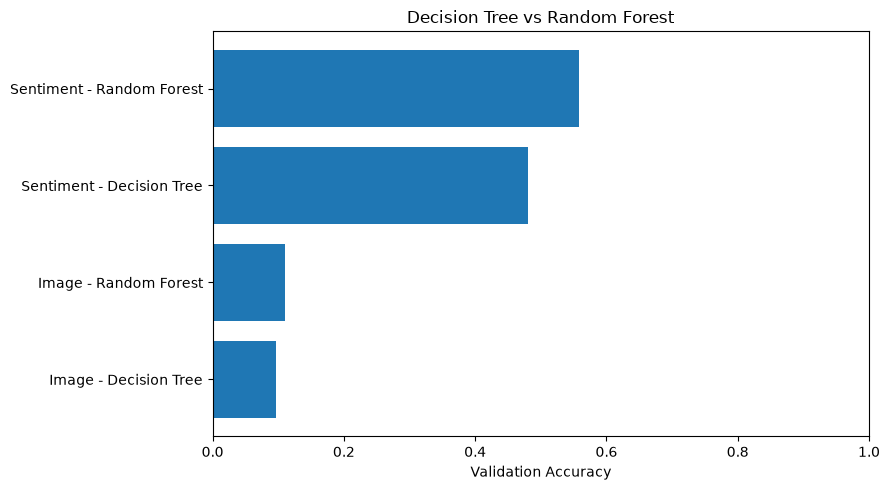

In [17]:
comparison_rows = []

for dataset, (Xtr, Xva, ytr, yva) in DATASETS_TREE.items():

    models = [
        ("Decision Tree", best_trees[dataset]),
        ("Random Forest", best_forests[dataset])
    ]

    for model_name, model in models:

        comparison_rows.append({
            "Dataset": dataset,
            "Model": model_name,
            "Training accuracy": accuracy_score(
                ytr, model.predict(Xtr)
            ),
            "Validation accuracy": accuracy_score(
                yva, model.predict(Xva)
            )
        })

comparison_df = pd.DataFrame(comparison_rows)

display(comparison_df)

plt.figure(figsize=(9, 5))

labels = [
    f"{row['Dataset']} - {row['Model']}"
    for _, row in comparison_df.iterrows()
]

plt.barh(
    labels,
    comparison_df["Validation accuracy"]
)

plt.xlabel("Validation Accuracy")
plt.title("Decision Tree vs Random Forest")
plt.xlim(0, 1)
plt.tight_layout()
plt.show()


Image - Decision Tree
              precision    recall  f1-score   support

           0       0.00      0.00      0.00        80
           1       0.06      0.10      0.07        80
           2       0.20      0.36      0.25        80
           3       0.18      0.14      0.16        80
           4       0.04      0.05      0.04        80
           5       0.38      0.29      0.33        80
           6       0.07      0.03      0.04        80
           7       0.03      0.07      0.04        80
           8       0.11      0.14      0.12        80
           9       0.04      0.06      0.05        80
          10       0.05      0.01      0.02        80
          11       0.14      0.15      0.14        80
          12       0.08      0.05      0.06        80
          13       0.19      0.16      0.18        80
          14       0.06      0.06      0.06        80
          15       0.05      0.39      0.09        80
          16       0.10      0.06      0.08        80
    

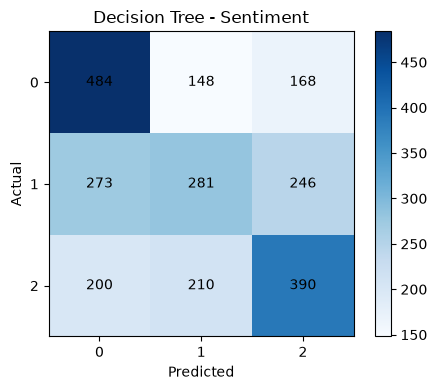


Sentiment - Random Forest
              precision    recall  f1-score   support

           0       0.57      0.68      0.62       800
           1       0.50      0.44      0.47       800
           2       0.59      0.56      0.58       800

    accuracy                           0.56      2400
   macro avg       0.56      0.56      0.55      2400
weighted avg       0.56      0.56      0.55      2400

Most common classification errors:
Actual 1 -> Predicted 0: 262
Actual 2 -> Predicted 1: 209
Actual 1 -> Predicted 2: 186
Actual 2 -> Predicted 0: 145
Actual 0 -> Predicted 1: 140


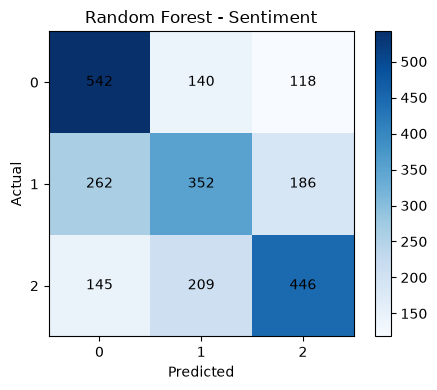

In [18]:
for dataset, (_, Xva, _, yva) in DATASETS_TREE.items():

    models = [
        ("Decision Tree", best_trees[dataset]),
        ("Random Forest", best_forests[dataset])
    ]

    for model_name, model in models:

        predictions = model.predict(Xva)

        print(f"\n{dataset} - {model_name}")

        print(
            classification_report(
                yva, predictions, zero_division=0
            )
        )

        labels = np.unique(yva)

        cm = confusion_matrix(
            yva, predictions, labels=labels
        )

        cm_errors = cm.copy()
        np.fill_diagonal(cm_errors, 0)

        indices = np.argsort(
            cm_errors.ravel()
        )[::-1][:5]

        print("Most common classification errors:")

        for index in indices:
            i, j = np.unravel_index(index, cm.shape)

            if cm_errors[i, j] > 0:
                print(
                    f"Actual {labels[i]} -> "
                    f"Predicted {labels[j]}: "
                    f"{cm_errors[i, j]}"
                )

        if dataset == "Sentiment":

            plt.figure(figsize=(5, 4))
            plt.imshow(cm, cmap="Blues")

            plt.xticks(range(3), labels)
            plt.yticks(range(3), labels)

            plt.xlabel("Predicted")
            plt.ylabel("Actual")
            plt.title(f"{model_name} - Sentiment")

            for i in range(3):
                for j in range(3):
                    plt.text(
                        j, i, cm[i, j],
                        ha="center", va="center"
                    )

            plt.colorbar()
            plt.tight_layout()
            plt.show()

### 2.4 Saving the results

In [20]:
out_dir = Path("results")
out_dir.mkdir(exist_ok=True)

tree_results_df.to_csv(
    out_dir / "decision_tree_experiments.csv",
    index=False
)

forest_results_df.to_csv(
    out_dir / "random_forest_experiments.csv",
    index=False
)

comparison_df.to_csv(
    out_dir / "part2_comparison.csv",
    index=False
)

print("Results saved to:", out_dir)

Results saved to: results
